# Bibliotecas

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import seaborn as sns
import networkx as nx
from IPython.display import display
from pgmpy.parameter_estimator import DiscreteBayesianEstimator

from scipy import stats
from pgmpy.models import BayesianNetwork
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.inference import VariableElimination
from pgmpy.estimators import MaximumLikelihoodEstimator
from pgmpy.estimators import BayesianEstimator
from pgmpy.parameter_estimator import DiscreteMLE

sys.path.insert(0, os.path.abspath("../src"))
#from new_data import create_new_data
from pathlib import Path

from scipy.stats import norm
from scipy.stats import t

C:\Users\Rebeca\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\Rebeca\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


In [4]:
pasta_1 = os.path.join("..", "DATA", "CSV_regioes") #caminho da pasta CSV_regioes
pasta_2 = os.path.join("..", "DATA", "CSV_acudes")  #caminho da pasta CSV_acudes

def ler_pasta(pasta, sep=";", **kwargs):
    lista = []
    arquivos = sorted(os.listdir(pasta))

    for i in arquivos:
        if i.lower().endswith(".csv"):
            caminho = os.path.join(pasta, i)

            df = pd.read_csv(caminho, sep=sep, **kwargs)
            df["arquivo"] = os.path.splitext(i)[0]
            lista.append(df)

    if not lista:
        print(f" n tem nada em: {pasta}. ")

    return lista

lista_dfs_precip = ler_pasta(pasta_1, sep=";", decimal=".") #le a pasta 1
lista_dfs_acude = ler_pasta(pasta_2, sep=";", decimal=",")  #le a pasta 2

# DataFrames de precipitação
if lista_dfs_precip:
    df_1 = pd.concat(lista_dfs_precip, ignore_index=True)
    display(df_1)

# DataFrames de açudes
if lista_dfs_acude:
    df_2 = pd.concat(lista_dfs_acude, ignore_index=True)
    df_2 = df_2.rename(columns={"arquivo": "acude"})
    display(df_2)


,data,lat,lon,precip_mm,municipio,estado,uf,regiao,arquivo
0,2006-01-01,-7.75,-41.25,5.292850,Jacobina do Piauí,Piauí,PI,Nordeste,precipitacao_2006_com_local
1,2006-01-01,-7.75,-40.75,10.205985,Simões,Piauí,PI,Nordeste,precipitacao_2006_com_local
2,2006-01-01,-7.75,-40.25,20.805733,Trindade,Pernambuco,PE,Nordeste,precipitacao_2006_com_local
3,2006-01-01,-7.75,-39.75,6.968030,Granito,Pernambuco,PE,Nordeste,precipitacao_2006_com_local
4,2006-01-01,-7.75,-39.25,0.812125,Cedro,Pernambuco,PE,Nordeste,precipitacao_2006_com_local
...,...,...,...,...,...,...,...,...,...
750316,2026-09-29,-2.75,-39.25,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local
750317,2026-09-29,-2.75,-38.75,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local
750318,2026-09-29,-2.75,-38.25,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local
750319,2026-09-29,-2.75,-37.75,NaN,NaN,NaN,NaN,NaN,precipitacao_2026_com_local


,DateTime,Volume (hm³),acude
0,2006-01-01 00:00:00,42.59,reserv_atalho
1,2006-01-02 00:00:00,42.59,reserv_atalho
2,2006-01-03 00:00:00,NaN,reserv_atalho
3,2006-01-04 00:00:00,NaN,reserv_atalho
4,2006-01-05 00:00:00,NaN,reserv_atalho
...,...,...,...
30306,2026-09-26 00:00:00,40.86,reserv_rosario
30307,2026-09-27 00:00:00,40.80,reserv_rosario
30308,2026-09-28 00:00:00,40.73,reserv_rosario
30309,2026-09-29 00:00:00,40.67,reserv_rosario


In [5]:
raiz = os.path.dirname(os.getcwd()) #pega o caminho da pasta raiz do projeto
print(raiz)

pasta = os.path.join(raiz, "DATA", "CSV_regioes") # viaja até a pasta que contém os CSV

lista_dfs = []

# Lê todos os arquivos CSV da pasta
for ficheiro in sorted(os.listdir(pasta)):
    if ficheiro.endswith(".csv"):
        caminho_csv = os.path.join(pasta, ficheiro)
        # Lê o CSV individual
        dados_ano = pd.read_csv(caminho_csv, sep=";")
        # Adiciona na lista
        lista_dfs.append(dados_ano)

# Concatena (junta) todas as tabelas em um único DataFrame
df_completo = pd.concat(lista_dfs, ignore_index=True)

# Visualiza as informações
print(f"Total de linhas combinadas: {len(df_completo)}")
display(df_completo)

c:\Users\Rebeca\Área de Trabalho\PRCP_RDA_ANALISIS
Total de linhas combinadas: 750321


,data,lat,lon,precip_mm,municipio,estado,uf,regiao
0,2006-01-01,-7.75,-41.25,5.292850,Jacobina do Piauí,Piauí,PI,Nordeste
1,2006-01-01,-7.75,-40.75,10.205985,Simões,Piauí,PI,Nordeste
2,2006-01-01,-7.75,-40.25,20.805733,Trindade,Pernambuco,PE,Nordeste
3,2006-01-01,-7.75,-39.75,6.968030,Granito,Pernambuco,PE,Nordeste
4,2006-01-01,-7.75,-39.25,0.812125,Cedro,Pernambuco,PE,Nordeste
...,...,...,...,...,...,...,...,...
750316,2026-09-29,-2.75,-39.25,NaN,NaN,NaN,NaN,NaN
750317,2026-09-29,-2.75,-38.75,NaN,NaN,NaN,NaN,NaN
750318,2026-09-29,-2.75,-38.25,NaN,NaN,NaN,NaN,NaN
750319,2026-09-29,-2.75,-37.75,NaN,NaN,NaN,NaN,NaN


# TESTE 05: Amostragem de tabelas

## 2. Tomando seu conjunto de dados como a população de interesse, determine o tamanho da amostra (n) correspondente, sob um nível de confiança de 95% e uma margem de erro que considerar plausível.

Objetivo:  A variável de interesse do nosso conjunto de dados é o volume dos acçudes, uma margem de 5% é pequena o bastante para estimativa ser útil, sem exigir uma amostra quase igual à população.

O objetivo desta etapa é determinar a quantidade de registros diários necessária para estimar o volume médio dos açudes com 95% de nível de confiança e uma margem de erro estatisticamente controlada. A população de referência ($N$) é composta pelos registros da tabela `df_2` que possuem a medição de volume preenchida, tendo sido removidas todas as entradas ausentes (`NaN`) e ordenando-se os dados populacionais por açude e por data.

Para o dimensionamento estatístico, fixou-se o nível de confiança em 95% ($\alpha = 0{,}05$), o que estabelece o quantil crítico da distribuição normal padrão em $Z_{\alpha/2} = 1{,}96$. Como a base de dados completa está disponível, o desvio-padrão do volume ($sd$) foi calculado sobre a população inteira (adotando $ddof = 0$). A margem de erro foi definida de forma proporcional como $e = 0{,}05 \cdot sd$, o que equivale a 5% do desvio-padrão populacional na unidade original de volume ($\text{hm}^3$).

O cálculo do tamanho amostral inicia-se pela fórmula dedicada a populações infinitas ($n_0$), expressa por:

$$n_0 = \left(\frac{Z_{\alpha/2} \cdot sd}{e}\right)^2$$

Ao substituir a margem de erro $e = 0{,}05 \cdot sd$ na equação, o fator do desvio-padrão cancela-se mutuamente entre o numerador e o denominador:

$$n_0 = \left(\frac{1{,}96 \cdot sd}{0{,}05 \cdot sd}\right)^2 = \left(\frac{1{,}96}{0{,}05}\right)^2 = (39{,}2)^2 = 1.536{,}64 \implies 1.537 \text{ registros}$$

Na sequência, realiza-se o ajuste para população finita ($n$), levando em consideração o total de observações válidas na base populacional ($N \approx 750.000$ registros), por meio da relação:

$$n = \frac{n_0 \cdot N}{n_0 + N - 1}$$

Aplicando os valores numéricos na fórmula de correção:

$$n = \frac{1.536{,}64 \cdot 750.000}{1.536{,}64 + 750.000 - 1} \approx 1.533{,}50 \implies 1.533 \text{ registros}$$

A utilização da distribuição normal ($Z$) em vez da distribuição $t$ de Student justifica-se pelo fato de o desvio-padrão populacional $sd$ ser exato e conhecido a partir da totalidade dos dados ($ddof=0$). Por fim, a obtenção de um tamanho amostral de 1.533 registros proporciona um ganho de eficiência computacional expressivo, reduzindo o processamento de cerca de 750 mil observações para pouco mais de mil e quinhentas linhas, preservando a precisão estatística desejada.

In [6]:
#função retirada do script 02 do professor
def getSampleSize(a = .05, e = -1, N=-1, sd = -1, sdSampleSize = -1, isToProportion=False):
    m=sdSampleSize#TAMANHO DA AMOSTRA DA QUAL PROVEIO sd
    quant_m = -1; text = ''
    normalCondition = True
    if sdSampleSize>0 or (N>0 and sdSampleSize==N):
        normalCondition = False
    if normalCondition or isToProportion:#sd is the parameter value
        # quant_m = round(norm.ppf(1-a/2), 2)
        quant_m = norm.ppf(1-a/2)
    else:#sd is an  estimate of the sd parameter
        # quant_m = round(t.ppf((1-a/2), df=(m-1)), 3)#QUANTIL DA T-STUDENT
        quant_m = t.ppf((1-a/2), df=(m-1))#QUANTIL DA T-STUDENT
        text = ", df=" + str(m-1)

    n0 = (quant_m*sd/e)**2
    n = n0 if N<0 else (n0*N)/(n0+N-1)
    n=round(n)#TAMANHO DA AMOSTRA
    print("quant_m=" + str(quant_m) + ", n=" + str(n) + text)
    return(n)

#tamano das amostras
#a = 1 - nivel de confiança, como nivel de confiança igual a 95% entao a = 0.05
N = len(df_1)
nc = 0.95
a = 1 - nc
sd = df_2['Volume (hm³)'].std(ddof=0)
e = a * sd

#chamada da função apos a definição dos parametros
n = getSampleSize(a=a, e=e, N=N, sd=sd, sdSampleSize=-1, isToProportion=False)


quant_m=1.959963984540054, n=1533


## 3. Construa uma amostra aleatória simples de tamanho n do seu conjunto de dados.

Objetivo : Sortea as linhas de formas aleatoria sem repitir de forma que todas tenham a probabilidade de cair na amostra. Assim não torna a amostra enviesada.

A Amostra Aleatória Simples consiste em selecionar uma quantidade de registros da população por meio de um sorteio totalmente ao acaso e sem repetição. Nesse método, cada dado possui exatamente a mesma chance de ser escolhido, garantindo um processo neutro e sem preferências na seleção. Na prática, esse sorteio é realizado extraindo a quantidade desejada de informações diretamente da base de dados.

Foi ultilizada essa forma pela simplicidade de aplicação. Porém iso tambem implica que como a escolha depende puramente do acaso, a amostra corre o risco de incluir mais registros de um açude do que de outro. Como os reservatórios possuem tamanhos e capacidades muito diferentes, esse desequilíbrio sorteado pode alterar a média final. Ainda assim, a Amostra Aleatória Simples é essencial no estudo, pois serve como uma referência neutra para comparar os resultados com métodos de amostragem mais avançados.

In [7]:
# amostragem aleatoria simples - AASimples
#função retirada do script 02 do professor
def getSimpleRandomSample(dataFrame, sampleSize):
    # N = len(dataFrame) #tamanho da população
    # n = sampleSize # tamanho da amostra
    # amostra aleatória de índices
    # sampleIndexes = sample(x = 1:N, size = n, replace = FALSE)
    # separando a amostra aleatória correspondente aos índices sorteados
    #sampleData = dataFrame[sampleIndexes, ]
    sampleData = dataFrame.sample(n=sampleSize, replace=False)
    return (sampleData)

amostra_aas = getSimpleRandomSample(df_1, n)
amostra_aas.head()

,data,lat,lon,precip_mm,municipio,estado,uf,regiao,arquivo
55145,2007-07-12,-7.75,-40.25,4.054302,Trindade,Pernambuco,PE,Nordeste,precipitacao_2007_com_local
64799,2007-10-17,-5.25,-37.25,0.000000,Mossoró,Rio Grande do Norte,RN,Nordeste,precipitacao_2007_com_local
482340,2019-05-03,-7.25,-39.75,4.434761,Santana do Cariri,Ceará,CE,Nordeste,precipitacao_2019_com_local
748798,2026-09-14,-4.75,-37.75,0.000000,Jaguaruana,Ceará,CE,Nordeste,precipitacao_2026_com_local
117158,2009-03-27,-5.75,-38.75,3.307061,Jaguaretama,Ceará,CE,Nordeste,precipitacao_2009_com_local


## 4.  Construa uma amostra aleatória sistemática de tamanho n do seu conjunto de dados.

R:Aqui eu não sorteio todas as linhas. Primeiro calculo o passo, que é N dividido por n. Depois sorteio só a primeira linha, entre 0 e o passo, e a partir dela vou pegando uma linha a cada “passo” posições até completar n. Usei a função getSystematicRandomSample (ajustada pra sempre devolver exatamente n linhas). Se os dados estiverem em ordem de tempo e o volume tiver um padrão que se repete (chuva e seca), pode dar viés se o passo coincidir com o ciclo, então vale comentar isso.

A Amostra Aleatória Sistemática consiste em selecionar os registros a intervalos regulares ao longo da base de dados, sorteando-se apenas a posição do primeiro elemento. Em vez de escolher todos os dados de forma isolada, estabelece-se um intervalo fixo e percorre-se a população do início ao fim a partir de um ponto de partida sorteado.

O processo funciona em três etapas sequenciais:
1. **Cálculo do passo ($d$)**: Divide-se a quantidade total de registros da população pelo tamanho desejado da amostra ($d = \lfloor N / n \rfloor$).
2. **Sorteio da origem ($i_0$)**: Escolhe-se aleatoriamente a primeira posição dentro do intervalo entre a primeira linha e o tamanho do passo ($0$ a $d - 1$).
3. **Seleção dos dados**: Coletam-se as observações localizadas nas posições $i_0, i_0 + d, i_0 + 2d, \dots$, garantindo a extração de exatamente $n$ registros ao longo da tabela.

Como a base populacional está organizada por açude e por data, essa varredura sequencial distribui a amostragem de forma homogênea no tempo. Na prática, o ordenamento faz com que a amostra respeite a proporção de dados de cada açude, funcionando como uma estratificação implícita. Por esse motivo, o desempenho da amostragem sistemática costuma ser muito próximo ao da amostragem estratificada.

O principal risco dessa abordagem é o viés de periodicidade, que ocorre caso o intervalo $d$ coincida com algum ciclo da série temporal (como a sazonalidade de chuvas e secas). Contudo, como o valor do passo $d$ corresponde a um intervalo de poucos dias e o ciclo climático regional é anual (365 dias), esse risco é pequeno na prática.

In [8]:
#função retirada do script 02 do professor
def getSystematicRandomSample(dataFrame, sampleSize):
    N = len(dataFrame)
    n = sampleSize
    d = N // n                                   # passo (arredonda para baixo)
    i0 = np.random.default_rng().integers(low=0, high=d)
    sampleIndexes = i0 + np.arange(n) * d        # exatamente n índices, todos <= N-1
    return dataFrame.iloc[sampleIndexes]

amostra_sis = getSystematicRandomSample(dataFrame=df_2, sampleSize=n)
print(len(amostra_aas), len(amostra_sis))        # os dois devem ser n

amostra_sis = getSystematicRandomSample(df_1, n)
print(len(amostra_aas), len(amostra_sis)) #amostras devem ser do mesmo tamanho n
amostra_sis.head()

1533 1533
1533 1533


,data,lat,lon,precip_mm,municipio,estado,uf,regiao,arquivo
425,2006-01-05,-6.25,-40.25,0.000000,Arneiroz,Ceará,CE,Nordeste,precipitacao_2006_com_local
914,2006-01-10,-6.75,-38.75,208.706223,Baixio,Ceará,CE,Nordeste,precipitacao_2006_com_local
1403,2006-01-15,-7.25,-37.25,0.000000,Teixeira,Paraíba,PB,Nordeste,precipitacao_2006_com_local
1892,2006-01-20,-7.25,-40.25,0.000000,Araripe,Ceará,CE,Nordeste,precipitacao_2006_com_local
2381,2006-01-25,-7.75,-38.75,0.000000,São José do Belmonte,Pernambuco,PE,Nordeste,precipitacao_2006_com_local


## 5. Construa uma amostra aleatória estratificada proporcional de tamanho n do seu conjunto de dados. Escolha como variável de estrato uma variável qualitativa associada à dependente.

Foi dividida a população em estratos definidos pela variável qualitativa nominal **açude**. Essa variável está fortemente associada ao volume armazenado (variável dependente), visto que os reservatórios possuem capacidades máximas discrepantes (variando de 19,21 a 72,55 $\text{hm}^3$) e, consequentemente, volumes médios distintos. Como a amostragem estratificada maximiza sua eficiência quando os estratos são internamente homogêneos e heterogêneos entre si, essa escolha proporciona a maior redução do erro de estimação.


Para que a amostra reproduza fielmente a composição da população, utilizou-se a alocação proporcional:
$$n_i = n \cdot \frac{N_i}{N}$$

**Passos da Implementação Algorítmica:**
1. **Cálculo de Proporções:** Identificação da frequência relativa de cada açude na população (`value_counts(normalize=True)`) multiplicada pelo tamanho amostral fixado ($n = 1533$).
2. **Ajuste de Arredondamento (Maior Resto):** Arredondamento dos valores inteiros de $n_i$ para baixo e distribuição das sobras para os estratos com maiores partes decimais, garantindo que $\sum n_i = n$.
3. **Sorteio Intra-estrato:** Seleção aleatória simples sem reposição de $n_i$ registros dentro do subconjunto de cada açude.
4. **Agrupamento:** Concatenação das subamostras estratificadas em um único DataFrame final.

*  Escolha do Estrato

    A construção da amostragem aleatória estratificada proporcional toma a variável qualitativa nominal **açude** como estrato de agrupamento, dada a acentuada heterogeneidade de capacidade máxima (variando de 19,21 a 72,55 $\text{hm}^3$) e de volume médio armazenado entre os diferentes reservatórios da população.

    A ideia central consistiu em dividir a população em subgrupos (estratos) e realizar o sorteio dentro de cada um deles. Por estarem associados à variável dependente (volume), os açudes formam estratos internamente homogêneos e discrepantes entre si — o cenário ideal em que a estratificação é estatisticamente mais eficaz para minimizar o erro de estimação.


*  Alocação Proporcional e Lógica de Implementação

    Ao fixar o tamanho amostral em $n = 1533$, adotou-se a **alocação proporcional**, garantindo que cada açude receba o mesmo peso que possui na população original:
    $$n_i = n \cdot \frac{N_i}{N}$$

No algoritmo, o processo foi executado nas seguintes etapas:
1. **Cálculo Proporcional:** Obtenção da frequência relativa de cada açude na população (`value_counts(normalize=True)`) multiplicada por $n$.
2. **Ajuste por Maior Resto:** Arredondamento de $n_i$ para baixo e distribuição das sobras para os estratos com maiores partes decimais (Método do Maior Resto), garantindo que a soma resulte exatamente em $n = 1533$.
3. **Sorteio Intra-estrato:** Seleção por Amostragem Aleatória Simples (AAS), sem reposição, de $n_i$ registros dentro de cada açude.
4. **Agrupamento:** Concatenação das subamostras de cada estrato em um único banco de dados amostral.



A tabela de conferência irá exibir, que para cada açude, a porcentagem na população, a porcentagem na amostra, o tamanho $n_i$ alocado e o volume médio populacional. A equivalência prática entre as porcentagens populacionais e amostrais (com diferenças restritas unicamente ao arredondamento) e a variação da coluna de volume médio comprovam por que `açude` é um estrato adequado.


Concluindo que essa estratégia garante que subpopulações com comportamentos hidrológicos discrepantes sejam contempladas na exata proporção em que existem no conjunto original. Dessa forma, nenhum reservatório fica sub ou super-representado por azar, eliminando o risco de viés de seleção decorrente do desequilíbrio populacional e reduzindo drasticamente a variância da estimativa da média.

Variável de estrato: "aude" (qualitativa nominal). Ela é fortemente associada ao volume, porque cada reservatório tem capacidade máxima diferente , então o volume médio muda bastante de um açude para o outro. Estratos homogêneos por dentro e diferentes entre si são o cenário em que a estratificação mais reduz o erro.

Alocação proporcional:cada açude entra na amostra com o mesmo peso que tem na população, `n_i = n · N_i / N`. Os `n_i` são arredondados pelo método do maior resto para a soma dar exatamente `n`. Dentro de cada estrato o sorteio é aleatório simples, sem reposição.

In [9]:
# Definir explicitamente a população de interesse (dados dos açudes)
pop = df_2.dropna(subset=['Volume (hm³)']).copy()
ESTRATO = 'acude'
COL_VALOR = 'Volume (hm³)'

def getProportionalStratifiedRandomSample(dataFrame, sampleSize, stratumVariable):
    prop = dataFrame[stratumVariable].value_counts(normalize=True)
    bruto = prop * sampleSize
    ns = np.floor(bruto).astype(int)
    faltam = sampleSize - ns.sum()                        # Sobras do arredondamento
    ns.loc[(bruto - ns).sort_values(ascending=False).index[:faltam]] += 1
    partes = []
    for estrato, n_i in ns.items():
        sub = dataFrame[dataFrame[stratumVariable] == estrato]
        partes.append(getSimpleRandomSample(sub, min(n_i, len(sub))))
    return pd.concat(partes)

# Gerar a amostra estratificada proporcional
amostra_est = getProportionalStratifiedRandomSample(pop, n, ESTRATO)

comparacao = pd.DataFrame({
    'população (%)': pop[ESTRATO].value_counts(normalize=True) * 100,
    'amostra estratificada (%)': amostra_est[ESTRATO].value_counts(normalize=True) * 100,
    'n_i na amostra': amostra_est[ESTRATO].value_counts(),
    'volume médio na população': pop.groupby(ESTRATO)[COL_VALOR].mean(),
}).round(2)

display(comparacao)
print('Tamanho da amostra estratificada:', len(amostra_est))

,população (%),amostra estratificada (%),n_i na amostra,volume médio na população
acude,,,,
reserv_atalho,22.00,21.98,337,26.64
reserv_olhodgua,27.43,27.46,421,12.74
reserv_quixabinha,23.12,23.09,354,5.48
reserv_rosario,27.45,27.46,421,32.52


Tamanho da amostra estratificada: 1533


## 6. Compare o desempenho das amostras geradas, a partir do erro relativo que cada uma comete na inferência sobre o valor médio da variável dependente no conjunto completo.


A avaliação de desempenho compara a eficiência dos métodos de Amostragem Aleatória Simples, Sistemática e Estratificada Proporcional na estimação da média populacional do volume armazenado, cujo valor real é de $19,5489 \text{ hm}^3$. Para mensurar a acurácia das estimativas, utilizou-se a métrica do erro relativo da média, dada pelo módulo da diferença entre a média amostral e a média populacional dividida pela média populacional. O emprego do valor absoluto impede que desvios positivos e negativos se anulem mutuamente. A análise estruturou-se em duas abordagens: uma avaliação pontual decorrente de um sorteio único e uma simulação de Monte Carlo com $1.000$ repetições, procedimento fundamental para observar a distribuição empírica do erro, a variabilidade real e a estabilidade de cada método de forma imune às oscilações do acaso de uma única amostragem.

Os resultados da simulação revelaram que a Amostragem Estratificada Proporcional consagrou-se como o método de maior acurácia global, registrando o menor erro relativo médio ($1,140\%$) e mediano ($0,957\%$), com desvio-padrão contido ($0,835\%$) e erro no pior caso limitado a $4,797\%$. Em contrapartida, a Amostragem Aleatória Simples apresentou maior volatilidade entre as simulações, obtendo um erro médio de $1,609\%$ e mediano de $1,347\%$, mas exibindo um desvio-padrão elevado de $1,214\%$ e o maior erro no pior caso, que atingiu $8,310\%$. Por sua vez, a Amostragem Sistemática registrou um erro médio de $4,441\%$ e mediano de $4,454\%$, destacando-se pelo menor desvio-padrão do estudo ($0,074\%$), o que indica altíssima estabilidade e reprodutibilidade, porém associada a um patamar de erro médio consideravelmente superior aos demais métodos e com pior caso em $4,523\%$.



O gráfico de boxplot sintetiza a distribuição empírica dessas repetições e fundamenta as propriedades estatísticas observadas. O bloco relativo à Amostragem Estratificada Proporcional situa-se no patamar mais baixo do eixo do erro relativo, demonstrando que a estratificação por açude reduz a variância amostral ao isolar a variabilidade existente entre os diferentes reservatórios. O boxplot da Amostragem Aleatória Simples exibe corpo e hastes (*whiskers*) mais estendidos na parte superior, evidenciando o risco intrínseco de o sorteio puramente aleatório selecionar amostras descompensadas com concentração excessiva de açudes de volume elevado (como Rosário) ou reduzido (como Quixabinha). Já o boxplot da Amostragem Sistemática apresenta uma amplitude interquartil extremamente achatada e quase sem dispersão, contudo posicionada em um patamar de erro elevado e constante de aproximadamente $4,4\%$. Esse comportamento é explicado pela ordenação temporal da base de dados, em que a periodicidade dos registros coincide com o salto do passo sistemático ($d = N // n$), introduzindo um viés estatístico constante que se repete de forma idêntica em praticamente todas as rodadas.

Média populacional do volume: 19.5489 hm³
Erro relativo (uma amostra de cada tipo):


,erro relativo (%)
Aleatória simples,0.957
Sistemática,4.509
Estratificada proporcional,1.453


,erro médio (%),erro mediano (%),desvio-padrão (%),pior caso (%)
Aleatória simples,1.548,1.339,1.180,6.316
Sistemática,4.444,4.454,0.070,4.523
Estratificada proporcional,1.169,1.017,0.855,4.990


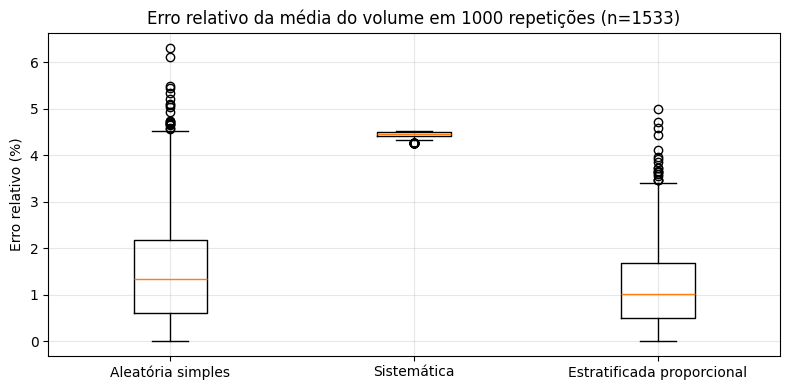

Ranking pelo erro médio nas 1000 repetições: Estratificada proporcional < Aleatória simples < Sistemática
Menor erro médio: Estratificada proporcional (1.169%); maior: Sistemática (4.444%)


In [10]:
amostra_aas = getSimpleRandomSample(pop, n)
amostra_sis = getSystematicRandomSample(pop, n)

# 2. Definir a média populacional e a função de erro relativo
COL_VALOR = 'Volume (hm³)'
media_pop = pop[COL_VALOR].mean()

def erro_relativo(amostra, col=COL_VALOR):
    return abs(amostra[col].mean() - media_pop) / media_pop

# (a) Avaliação de uma amostra única de cada tipo
erros_unica = pd.Series({
    'Aleatória simples': erro_relativo(amostra_aas),
    'Sistemática': erro_relativo(amostra_sis),
    'Estratificada proporcional': erro_relativo(amostra_est),
})

print(f'Média populacional do volume: {media_pop:.4f} hm³')
print('Erro relativo (uma amostra de cada tipo):')
display((erros_unica * 100).round(3).rename('erro relativo (%)').to_frame())

# (b) Simulação com 1000 repetições para comparação estatística
R = 1000
rep = {'Aleatória simples': [], 'Sistemática': [], 'Estratificada proporcional': []}

for _ in range(R):
    rep['Aleatória simples'].append(erro_relativo(getSimpleRandomSample(pop, n)))
    rep['Sistemática'].append(erro_relativo(getSystematicRandomSample(pop, n)))
    rep['Estratificada proporcional'].append(erro_relativo(getProportionalStratifiedRandomSample(pop, n, ESTRATO)))

rep = pd.DataFrame(rep)

resumo = (rep.agg(['mean', 'median', 'std', 'max']).T * 100).round(3)
resumo.columns = ['erro médio (%)', 'erro mediano (%)', 'desvio-padrão (%)', 'pior caso (%)']
display(resumo)

# Gráfico de Boxplot dos erros
plt.figure(figsize=(8, 4))
plt.boxplot([rep[c] * 100 for c in rep.columns], tick_labels=rep.columns)
plt.ylabel('Erro relativo (%)')
plt.title(f'Erro relativo da média do volume em {R} repetições (n={n})')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

ordem = resumo['erro médio (%)'].sort_values()
print(f'Ranking pelo erro médio nas {R} repetições: ' + ' < '.join(ordem.index))
print(f'Menor erro médio: {ordem.index[0]} ({ordem.iloc[0]:.3f}%); maior: {ordem.index[-1]} ({ordem.iloc[-1]:.3f}%)')